# 1 · Transcription

Transcribes the scrapbook images in **`input_images/`** with Claude, following the rules in
**`transcription_rules.md`**.

- Only images listed in **`input_image_manifest.csv`** are processed (column `File name`).
- Accepted formats: JPG, PNG, TIFF, PDF (each PDF page is treated as a separate page image).
- Each clipping becomes its own Markdown file in **`output_transcription_md/`**, named
  `{image}_r01.md`, `{image}_r02.md`, … with the YAML front matter the rules define.
- Every clipping gets a row in **`output_transcr_manifest.csv`**. An image that already appears there
  is **not** processed again, so after adding new images to the folder and the input manifest you
  can simply re-run this notebook.

The code is in `transcribe.py`; you do not need to open it.

## Setup

All settings shared by the three notebooks (API keys, Claude model, embedding model, folder names) live in
**`pipeline.env`** in this folder. Open it, fill in your keys, choose the model, save, then run this cell.
If you change `pipeline.env` later, just run this cell again.

In [1]:
from pipeline_common import load_settings
import transcribe

settings = load_settings()

Claude model      : claude-opus-5-5  (effort: high)
Embeddings        : voyage / voyage-3.5
ANTHROPIC_API_KEY : set (...9AAA)
VOYAGE_API_KEY    : set (...3sAq)
Project folder    : /Users/rfreedma/Documents/CRIM_Python/Liszt_Transcription_Chroma


## Run options

- **`USE_BATCH`**: `True` (normal) sends all pages together through Anthropic's **Batch API**, at **half the
  price**. Results usually arrive within an hour (at most 24 hours) and are written when you run
  **Step 2b**. `False` transcribes one page at a time right now, at full price. Useful for a quick test.
- **`FORCE_REPROCESS`**: `False` (normal) transcribes only images not yet in the output manifest.
  `True` re-transcribes **every** image in the input manifest. The earlier files are not deleted: they are moved to
  `output_transcription_md/_superseded/<date_time>/`, and their manifest rows (including any *Reviewed* marks) are replaced.
- **`MAX_IMAGES`**: set to a small number (e.g. `2`) to try things out first; `None` processes everything.
- **`COPY_MANIFEST_COLUMNS`**: columns of the input manifest to copy into each transcription's YAML
  (and so into the database, for filtering). Format: `{"Column name in CSV": "yaml_key"}`. Use `{}` for none.

In [2]:
USE_BATCH = False
FORCE_REPROCESS = True
MAX_IMAGES = None
COPY_MANIFEST_COLUMNS = {}

## Step 1 · Check what will be processed

No API calls are made here.

In [3]:
todo = transcribe.plan_work(settings, force=FORCE_REPROCESS, limit=MAX_IMAGES)

Images listed in manifest   : 10
Already transcribed         : 10
To process on this run      : 10   (FORCE_REPROCESS is on)

Will process: GSA_59_66_pages_19_-_28_page_19.pdf, GSA_59_66_pages_19_-_28_page_20.pdf, GSA_59_66_pages_19_-_28_page_21.pdf, GSA_59_66_pages_19_-_28_page_22.pdf, GSA_59_66_pages_19_-_28_page_23.pdf, GSA_59_66_pages_19_-_28_page_24.pdf, GSA_59_66_pages_19_-_28_page_25.pdf, GSA_59_66_pages_19_-_28_page_26.pdf, GSA_59_66_pages_19_-_28_page_27.pdf, GSA_59_66_pages_19_-_28_page_28.pdf


*Optional:* see a page exactly as Claude will receive it (after rotation, shrinking and conversion).

GSA_59_66_pages_19_-_28_page_19: 1653 x 2338 px, 0.3 MB


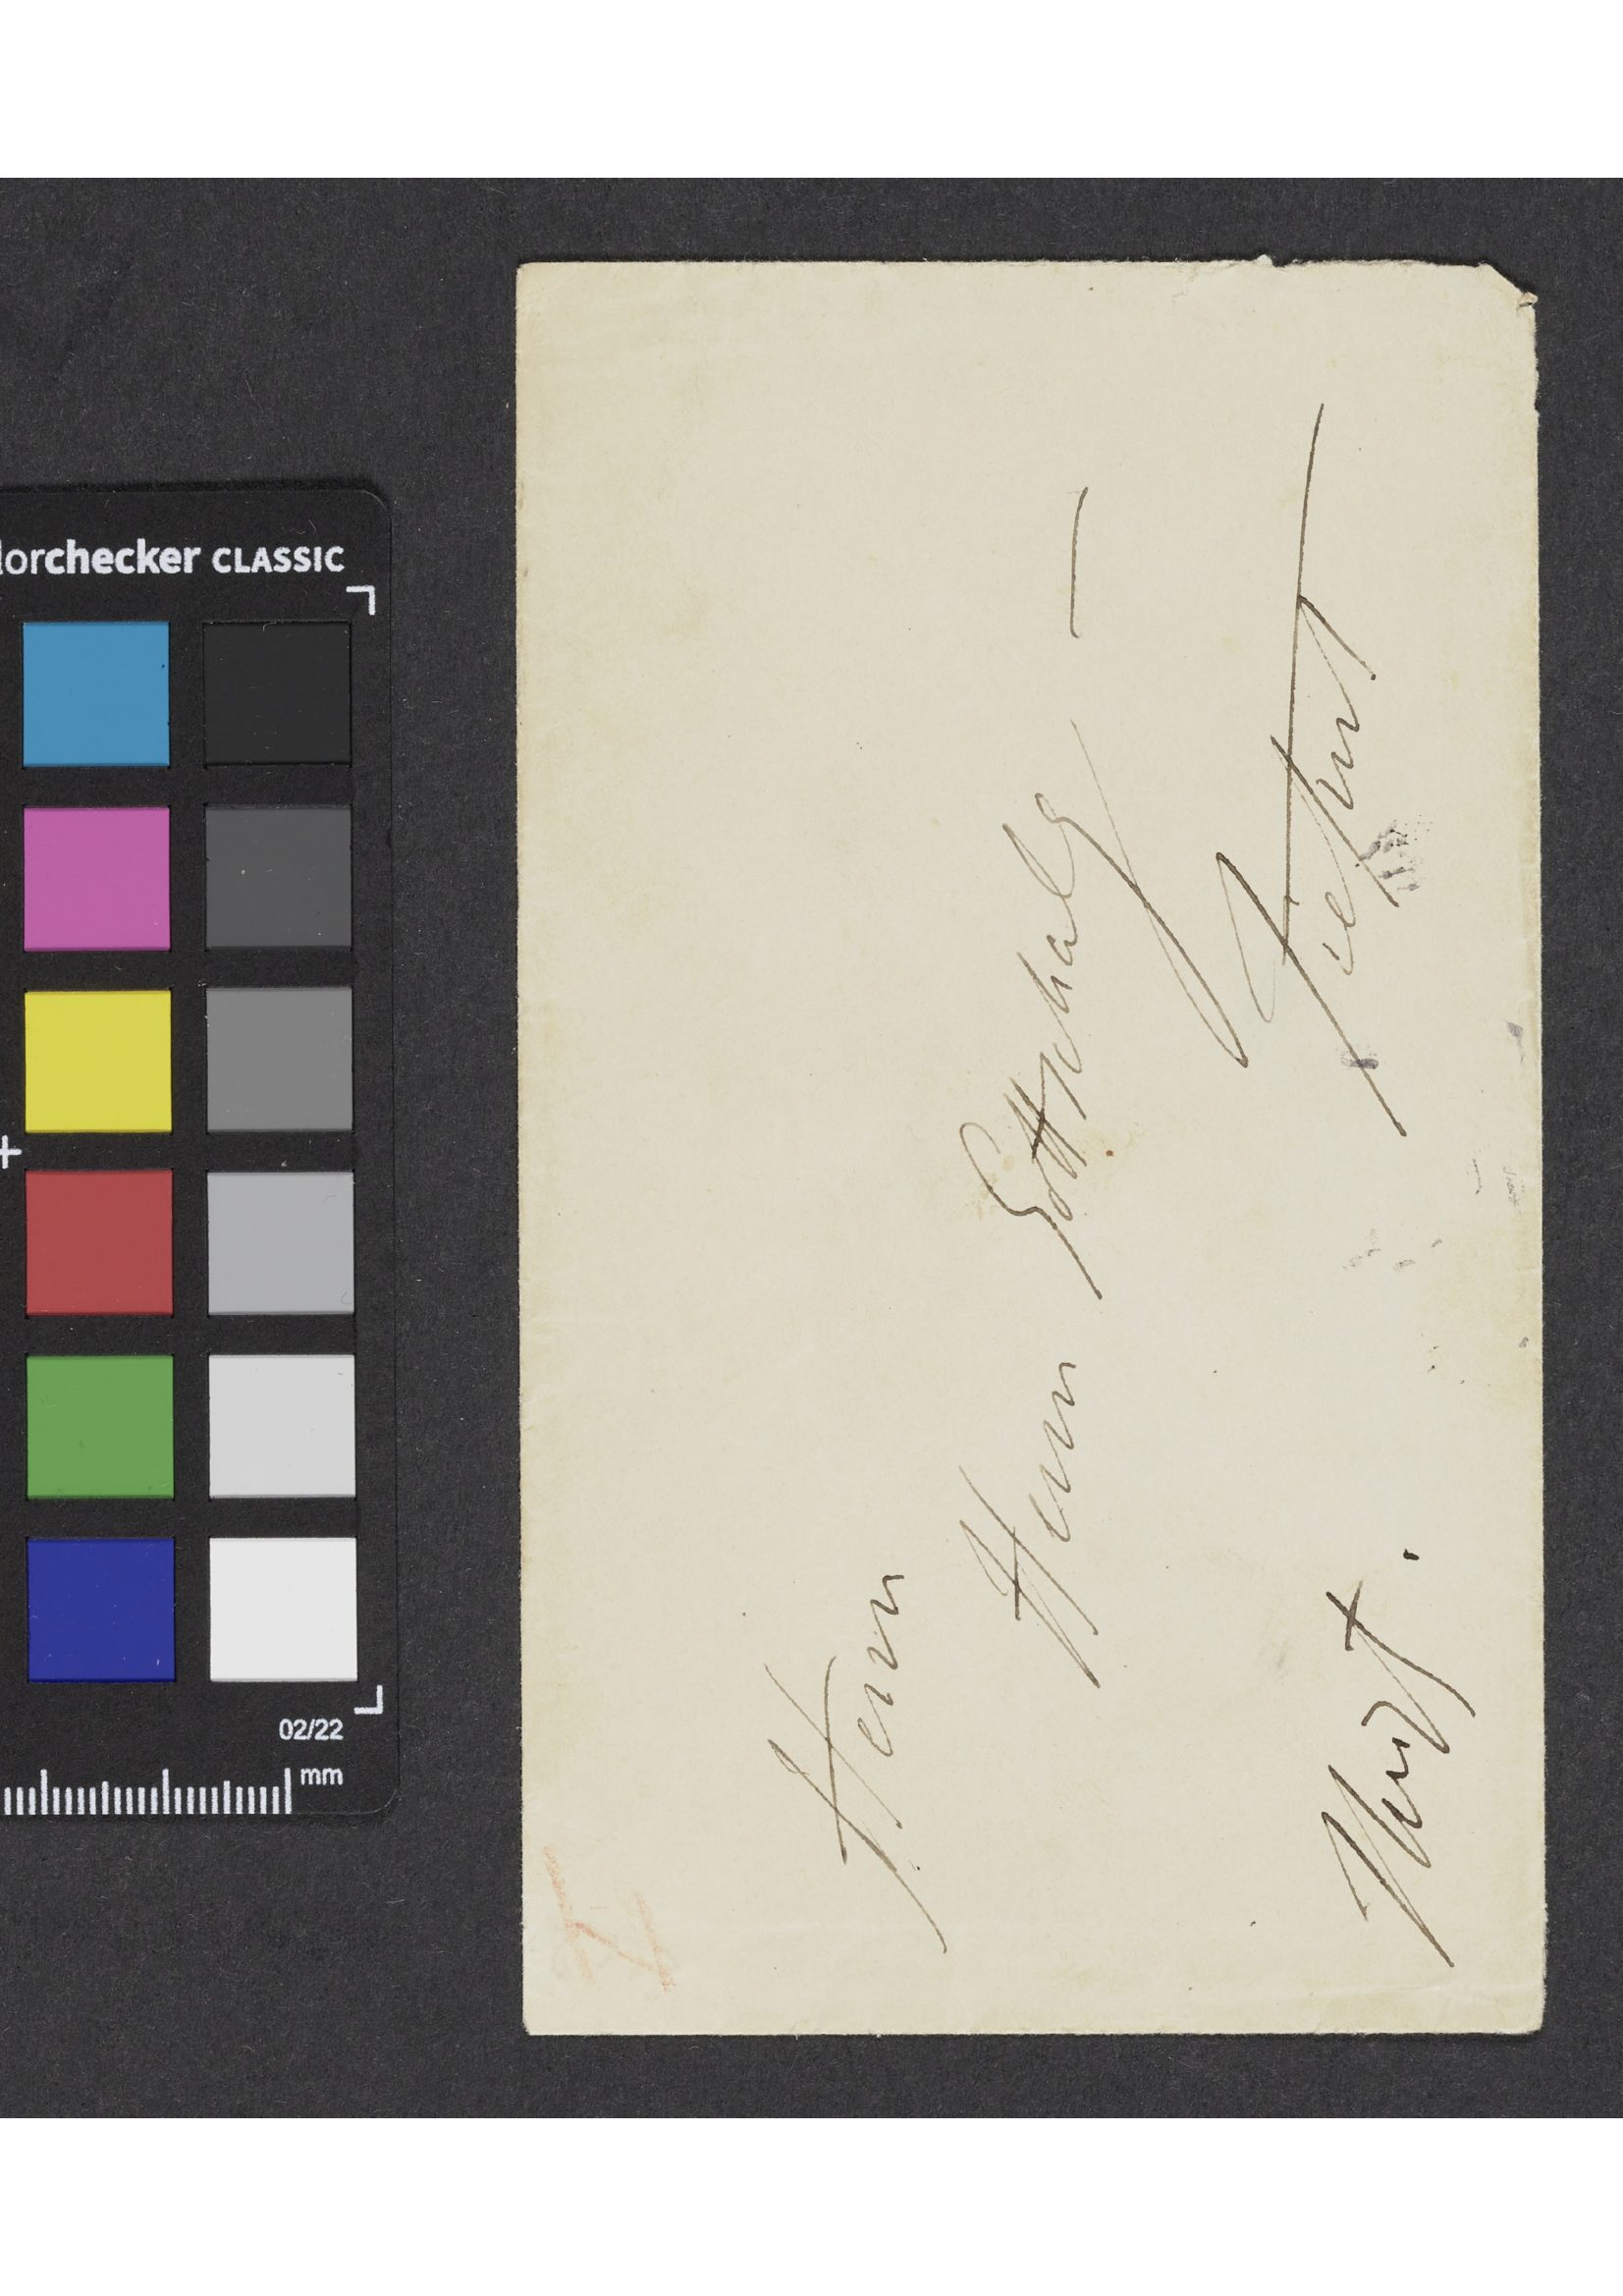

In [4]:
if todo:
    transcribe.preview_page(settings, todo[0])

## Step 2 · Transcribe  (uses the Claude API)

- **Batch mode** (`USE_BATCH = True`): this cell uploads the pages and finishes in a few seconds.
  The batch ID is saved in `pending_batch.json`, so you can close the notebook or restart Jupyter.
  Then go to **Step 2b**.
- **Immediate mode** (`USE_BATCH = False`): this cell transcribes page by page and saves after every
  image, so you can stop and restart at any time.

In both modes, images that fail are simply offered again on the next run.

In [5]:
if USE_BATCH:
    transcribe.submit_batch(settings, todo, force=FORCE_REPROCESS, copy_manifest_columns=COPY_MANIFEST_COLUMNS)
else:
    transcribe.transcribe_now(settings, todo, force=FORCE_REPROCESS, copy_manifest_columns=COPY_MANIFEST_COLUMNS)

[1/10] GSA_59_66_pages_19_-_28_page_19.pdf
    GSA_59_66_pages_19_-_28_page_19: 1 item(s)
[2/10] GSA_59_66_pages_19_-_28_page_20.pdf
    GSA_59_66_pages_19_-_28_page_20: 1 item(s)
[3/10] GSA_59_66_pages_19_-_28_page_21.pdf
    GSA_59_66_pages_19_-_28_page_21: 1 item(s)
[4/10] GSA_59_66_pages_19_-_28_page_22.pdf
    GSA_59_66_pages_19_-_28_page_22: 1 item(s)
[5/10] GSA_59_66_pages_19_-_28_page_23.pdf
    GSA_59_66_pages_19_-_28_page_23: 1 item(s)
[6/10] GSA_59_66_pages_19_-_28_page_24.pdf
    GSA_59_66_pages_19_-_28_page_24: 1 item(s)
[7/10] GSA_59_66_pages_19_-_28_page_25.pdf
    GSA_59_66_pages_19_-_28_page_25: 1 item(s)
[8/10] GSA_59_66_pages_19_-_28_page_26.pdf
    GSA_59_66_pages_19_-_28_page_26: 1 item(s)
[9/10] GSA_59_66_pages_19_-_28_page_27.pdf
    GSA_59_66_pages_19_-_28_page_27: 1 item(s)
[10/10] GSA_59_66_pages_19_-_28_page_28.pdf
    GSA_59_66_pages_19_-_28_page_28: 1 item(s)

Done. 10 of 10 image(s) transcribed.


## Step 2b · Collect batch results

Run this cell any time after submitting a batch. If the batch is still running it reports progress;
run it again later. When the batch has finished it writes the transcriptions and updates the
output manifest. Only the **Setup** cell needs to be run first (the batch remembers its own options).

To cancel a waiting batch instead: `transcribe.cancel_batch(settings)`.

In [6]:
transcribe.collect_batch(settings)

No batch is waiting to be collected.


## Step 3 · Review

The last rows of the output manifest, then one transcription (change the file name to look at another).
Files with `revision: true` contain flagged passages listed under **Para revisión**.

In [7]:
transcribe.show_manifest(settings)

10 row(s) in output_transcr_manifest.csv


,File name,Source image,Item no. on page,Document type,Sender,Recipient,Place,Date (YYYY-MM-DD),Date source,Title,Language,Word count (body),Reviewed,Model,Processed at,Notes
0,GSA_59_66_pages_19_-_28_page_19_r01.md,GSA_59_66_pages_19_-_28_page_19.pdf,1,envelope,,Gottschalg,Tiefurt,,absent,"Envelope addressed to Herrn Gottschalg, Tiefurt",German,8,no,claude-opus-5-5,2026-11-02,flagged for review
1,GSA_59_66_pages_19_-_28_page_20_r01.md,GSA_59_66_pages_19_-_28_page_20.pdf,1,envelope,,,,,absent,"Envelope, back",,14,no,claude-opus-5-5,2026-11-02,flagged for review
2,GSA_59_66_pages_19_-_28_page_21_r01.md,GSA_59_66_pages_19_-_28_page_21.pdf,1,letter,,,,,absent,"Letter, page 1",German,72,no,claude-opus-5-5,2026-11-02,flagged for review
3,GSA_59_66_pages_19_-_28_page_22_r01.md,GSA_59_66_pages_19_-_28_page_22.pdf,1,letter,,,,,absent,"Letter, continuation page",German,90,no,claude-opus-5-5,2026-11-02,flagged for review
4,GSA_59_66_pages_19_-_28_page_23_r01.md,GSA_59_66_pages_19_-_28_page_23.pdf,1,letter,,,,,absent,"Letter, continuation page",German,120,no,claude-opus-5-5,2026-11-02,flagged for review
5,GSA_59_66_pages_19_-_28_page_24_r01.md,GSA_59_66_pages_19_-_28_page_24.pdf,1,letter,,,,,absent,"Letter, continuation page",German,200,no,claude-opus-5-5,2026-11-02,flagged for review
6,GSA_59_66_pages_19_-_28_page_25_r01.md,GSA_59_66_pages_19_-_28_page_25.pdf,1,letter,,,,,absent,"Letter, continuation page",German,105,no,claude-opus-5-5,2026-11-02,flagged for review
7,GSA_59_66_pages_19_-_28_page_26_r01.md,GSA_59_66_pages_19_-_28_page_26.pdf,1,letter,,,,,absent,"Letter, continuation page",German,103,no,claude-opus-5-5,2026-11-02,flagged for review
8,GSA_59_66_pages_19_-_28_page_27_r01.md,GSA_59_66_pages_19_-_28_page_27.pdf,1,letter,F. Liszt,,Rom,,written,"Letter from F. Liszt, Rom, closing page with p...",German,88,no,claude-opus-5-5,2026-11-02,flagged for review
9,GSA_59_66_pages_19_-_28_page_28_r01.md,GSA_59_66_pages_19_-_28_page_28.pdf,1,other,,,,,absent,Blank page,,0,no,claude-opus-5-5,2026-11-02,


In [9]:
transcribe.show_transcription(settings, "GSA_59_66_pages_19_-_28_page_24_r01.md")

source_image: GSA_59_66_pages_19_-_28_page_24.pdf
item: 1
document_type: letter
sender: None
recipient: None
place: None
date: None
date_source: absent
title: Letter, continuation page
language: German
needs_review: True
model: claude-opus-5-5
processed: 2026-11-02


# Letter, continuation page  
  
[Description: letter page, single leaf of ruled blue-grey paper; brown ink, German text in a cursive hand; musical notation in the upper half (organ system of two staves and a separate pedal staff), text below; ink blot below the pedal staff.]  
  
## Transcription  
  
Einstweilen hier die [?ersten?] Accorde:  
  
F. dur Lento assai  
  
[Musical notation: two staves joined by a brace, labelled "Orgel" at left; upper staff treble clef, key signature of 1 flat, common time (C); lower staff bass clef, key signature of 1 flat, common time (C); c. 7 bars ending with a double bar; chords in half and whole notes, thickening towards the end; a sign resembling a sharp (?) above the lower staff near its beginning; ties or slurs below some notes of the lower staff.]  
  
[Musical notation: one staff labelled [?Pedal?] at left; bass clef (?), common time (?); c. 8 bars ending with a double bar; single notes in half and whole notes with ties or slurs; one note written below the staff near an ink blot at the right end.]  
  
und an einem schönen Mai abend  
spielen Sie das Ganze mit [?Groß?] in  
Ihrer [?Tiefurter?] Kirche, und laßen Sie mich  
beide mit Orgel und Posaune fortleben!  
Es ist mir aufgefallen daß Ihr  
[?Nahme?] nicht unter den Mitarbeitern  
des Jubel Album – Johan̄ Schneider's genannt  
ist. Wen̄ noch Zeit und Platz  
dazu vorhanden, [?Kön̄ten?] Sie vielleicht  
Ihr Arrangement der Fuge aus der  
[?Dante?] Sinfonie (mit dem Schluß der  
  
## For review  
  
- "Einstweilen hier die [?ersten?] Accorde": letterforms of "ersten" compressed; reading probable but not certain.  
- Musical notation: number of bars, time signatures and the clef of the pedal staff are uncertain; the label "[?Pedal?]" is partly cramped at the edge.  
- "mit [?Groß?] in": proper noun (?) not certain; could be read with a different ending.  
- "Ihrer [?Tiefurter?] Kirche": place name; ending of the word not clearly formed.  
- "[?Nahme?] nicht unter den Mitarbeitern": spelling with or without "h" not certain.  
- "Johan̄ Schneider's": proper noun; reading probable, macron over n and apostrophe to be checked.  
- "des Jubel Album": "des" could also be read "der".  
- "[?Kön̄ten?] Sie vielleicht": initial letter case and macron uncertain.  
- "aus der [?Dante?] Sinfonie": proper noun; first letter and form of the word not certain.  
